# Estudo 01 – Ruído, autocorrelação e por que "significativo" não é "lucrativo"

Notebook de estudo, **fora do protocolo**. Quase tudo aqui usa dados **simulados**, em que *sabemos* a verdade e podemos ver como as ferramentas se comportam. Só a última seção usa o WIN real, e apenas até 2024 (o período de desenvolvimento).

Perguntas que o notebook responde:

1. O que é correlação e o que é autocorrelação?
2. Se um número é medido em dados finitos, quanto ele "balança" só por acaso? (a régua 2/√n)
3. O que é um teste de hipótese e um p-valor?
4. Por que testar muitas coisas engana? (comparações múltiplas, a "maldição do vencedor")
5. Quando a régua 2/√n mente? (caudas gordas × agrupamento de volatilidade)
6. Como uma correlação vira acurácia e pontos, e quanto precisa para pagar o custo?
7. O que isso diz sobre o WIN em cada tamanho de candle?

**Como usar:** rode célula por célula. As células marcadas com **EXPERIMENTE** têm parâmetros para você mudar e ver o que acontece. Leitura recomendada junto: *Forecasting: Principles and Practice* (otexts.com/fpp3), cap. 2.8–2.9 (autocorrelação e ruído branco).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path
from scipy import stats

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA))
import tt1_comum as t
sys.path.append(str(PASTA / "frentes" / "estatistico"))
import custos as cu                                   # modelo de custo (cenários 2,5 / 7,5 / 12,5 pts)

rng = np.random.default_rng(42)
AZUL, LARANJA, VERDE, VIOLETA, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})

def rho1(x):
    "Autocorrelação de defasagem 1. Aceita um vetor ou uma matriz (uma série por linha)."
    x = np.atleast_2d(x); x = x - x.mean(axis=1, keepdims=True)
    return (x[:, 1:] * x[:, :-1]).sum(axis=1) / (x ** 2).sum(axis=1)

## 1. Correlação

A **correlação** (ρ, "rô") mede o quanto duas variáveis andam juntas **em linha reta**, numa escala de −1 a +1:

- **+1:** sempre que uma está acima da média dela, a outra também está, na mesma proporção;
- **−1:** sempre em sentidos opostos;
- **0:** saber uma não diz nada (linearmente) sobre a outra.

Em fórmula, é a média do produto das duas variáveis **padronizadas** (cada uma menos a média, dividida pelo desvio-padrão):

$$\rho = \text{média}\left(\frac{x - \bar x}{s_x}\cdot\frac{y - \bar y}{s_y}\right)$$

Se os dois desvios costumam ter o mesmo sinal, os produtos são positivos e ρ > 0. Veja como fica a nuvem de pontos com diferentes valores de ρ, sobretudo **ρ = 0,05**:

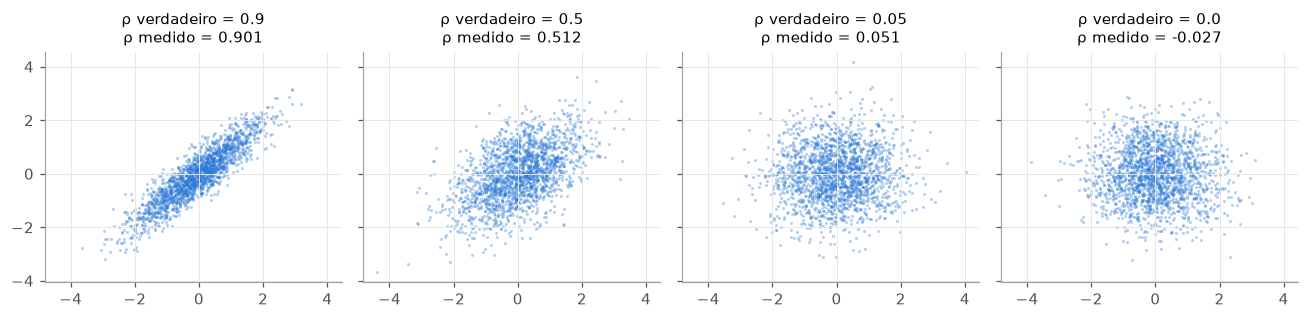

In [2]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3), sharex=True, sharey=True)
for ax, r in zip(axs, [0.9, 0.5, 0.05, 0.0]):
    x = rng.standard_normal(2000)
    y = r * x + np.sqrt(1 - r**2) * rng.standard_normal(2000)    # constrói y com correlação r
    ax.scatter(x, y, s=4, alpha=0.35, color=AZUL, linewidths=0)
    ax.set_title(f"ρ verdadeiro = {r}\nρ medido = {np.corrcoef(x, y)[0, 1]:.3f}", fontsize=10)
fig.tight_layout(); plt.show()

**Leitura:** com ρ = 0,05 a nuvem é indistinguível de ρ = 0 a olho nu. E ρ = 0,05 já seria **3 a 4 vezes maior** que qualquer autocorrelação medida no WIN (Seção 8). Os efeitos que procuramos em mercado são desse tamanho: invisíveis no gráfico, só aparecem com muitos dados e estatística.

Repare também que o "ρ medido" não é exatamente o verdadeiro. Essa diferença é o **ruído amostral** (Seção 3).

## 2. Autocorrelação: a série correlacionada com ela mesma

A **autocorrelação de defasagem 1** (ρ₁) é a correlação entre cada retorno r(t) e o seguinte, r(t+1). Forme os pares (r₁, r₂), (r₂, r₃), (r₃, r₄)… e calcule a correlação deles.

| ρ₁ | Nome no mercado | Em palavras |
|---|---|---|
| > 0 | **momentum** | candle de alta tende a ser seguido de alta |
| < 0 | **reversão** | alta tende a ser seguida de baixa |
| ≈ 0 | passeio aleatório | o último candle não diz nada sobre o próximo |

O modelo mais simples com autocorrelação é o **AR(1)**: r(t+1) = φ·r(t) + ε(t+1), em que ε é ruído puro. Nele, **φ é a própria autocorrelação ρ₁**. É exatamente essa estrutura que a parte AR do ARIMA tenta explorar: se ρ₁ ≈ 0, não há nada para o modelo usar, qualquer que seja a configuração.

**EXPERIMENTE:** mude os valores de `PHIS`.

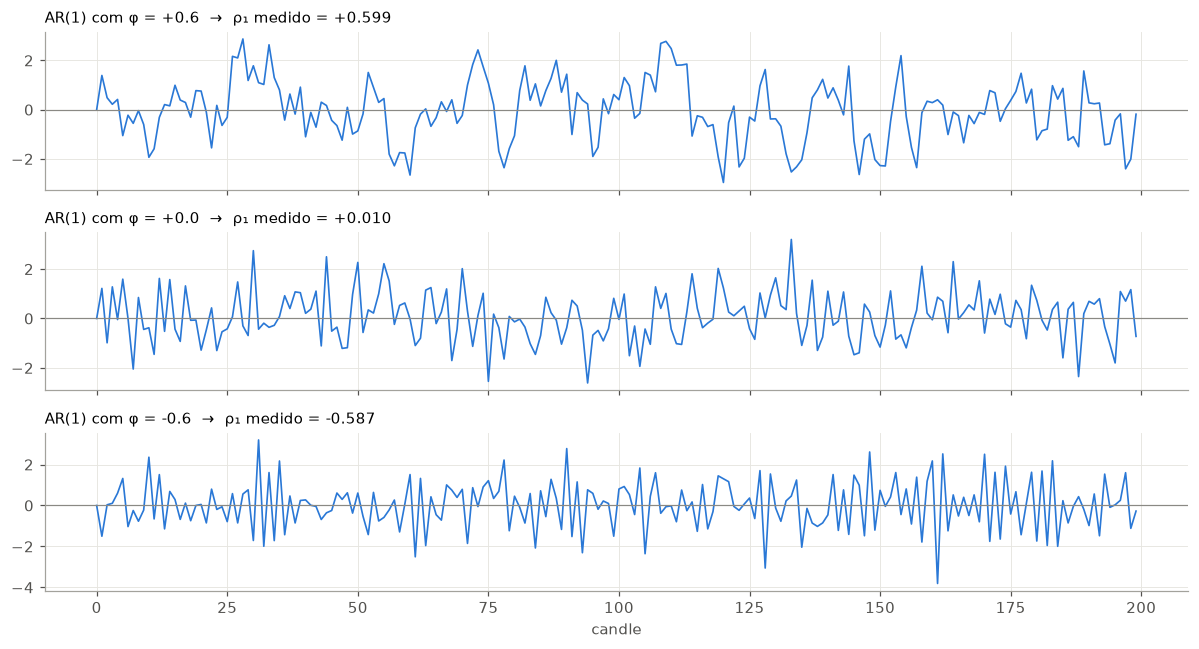

In [3]:
PHIS = [0.6, 0.0, -0.6]
n = 200
fig, axs = plt.subplots(len(PHIS), 1, figsize=(11, 6), sharex=True)
for ax, phi in zip(axs, PHIS):
    eps = rng.standard_normal(n); r = np.zeros(n)
    for i in range(1, n):
        r[i] = phi * r[i - 1] + eps[i]
    ax.plot(r, color=AZUL, lw=1.1); ax.axhline(0, color=CINZA, lw=0.8)
    ax.set_title(f"AR(1) com φ = {phi:+.1f}  →  ρ₁ medido = {rho1(r)[0]:+.3f}", fontsize=10, loc="left")
axs[-1].set_xlabel("candle"); fig.tight_layout(); plt.show()

**Leitura:** com φ = +0,6 a série faz "ondas" (persistência); com φ = −0,6 ela fica "serrilhada" (cada movimento tende a ser desfeito); com φ = 0 é ruído puro. Uma série de retornos reais do WIN se parece com a do meio.

## 3. Ruído amostral: quanto um número balança só por acaso

Jogue uma moeda honesta 100 vezes: você não vai tirar exatamente 50 caras. 46 ou 55 é normal. Do mesmo jeito, numa série em que a autocorrelação **verdadeira é exatamente zero**, o ρ₁ **medido** não vai dar zero.

Experimento: gerar 2.000 séries de ruído puro, cada uma com n = 10.000 retornos, e medir o ρ₁ de cada uma.

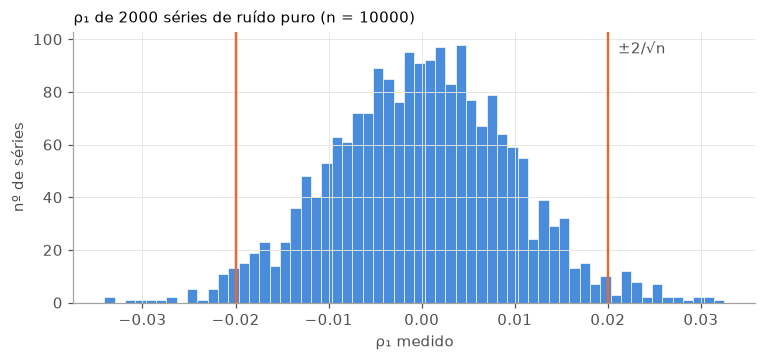

desvio-padrão dos ρ₁ medidos: 0.0096   (1/√n = 0.0100)
fração dentro de ±2/√n: 95.8%


In [4]:
R, n = 2000, 10_000
X = rng.standard_normal((R, n))                 # 2000 séries de ruído puro (ρ₁ verdadeiro = 0)
r1 = rho1(X)
faixa = 2 / np.sqrt(n)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(r1, bins=60, color=AZUL, alpha=0.85, edgecolor="white", linewidth=0.5)
for s in (-1, 1):
    ax.axvline(s * faixa, color=LARANJA, lw=1.6)
ax.text(faixa, ax.get_ylim()[1] * 0.92, "  ±2/√n", color="#52514e")
ax.set_xlabel("ρ₁ medido"); ax.set_ylabel("nº de séries")
ax.set_title(f"ρ₁ de {R} séries de ruído puro (n = {n})", loc="left", fontsize=10)
plt.show()
print(f"desvio-padrão dos ρ₁ medidos: {r1.std():.4f}   (1/√n = {1/np.sqrt(n):.4f})")
print(f"fração dentro de ±2/√n: {np.mean(np.abs(r1) < faixa):.1%}")

**Leitura:**

- Mesmo sem nenhuma estrutura, os ρ₁ medidos se espalham em torno de zero, com desvio-padrão **≈ 1/√n**.
- Cerca de **95%** deles caem dentro de **±2/√n**. Essa é a "faixa de ruído" da tabela que discutimos. A banda azul do gráfico de ACF (função de autocorrelação) que o `statsmodels` desenha é exatamente isso.
- Um valor **fora** da faixa é "estatisticamente significativo": seria raro (≈ 5% das vezes) se fosse só ruído.

Quanto mais dados, mais estreita a faixa, na proporção **1/√n**: para reduzir o ruído pela metade é preciso **4 vezes** mais dados.

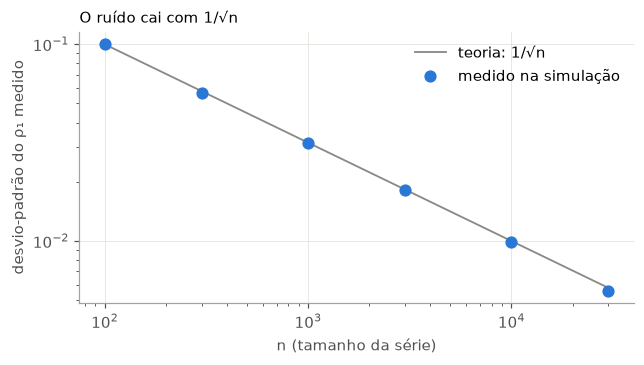

In [5]:
ns = [100, 300, 1_000, 3_000, 10_000, 30_000]
dp = [rho1(rng.standard_normal((1000, k))).std() for k in ns]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.loglog(ns, 1 / np.sqrt(ns), color=CINZA, lw=1.2, label="teoria: 1/√n")
ax.loglog(ns, dp, "o", color=AZUL, ms=7, label="medido na simulação")
ax.set_xlabel("n (tamanho da série)"); ax.set_ylabel("desvio-padrão do ρ₁ medido")
ax.legend(frameon=False); ax.set_title("O ruído cai com 1/√n", loc="left", fontsize=10); plt.show()

Por isso, no WIN, a faixa em 1 min (n ≈ 500 mil candles) é ±0,003, e em 120 min (n ≈ 3 mil) é ±0,035: **10 vezes** mais larga, porque há 150 vezes menos dados. Candles maiores custam menos por operação, mas deixam a estimativa muito mais ruidosa.

## 4. Teste de hipótese e p-valor, em linguagem simples

1. **Hipótese nula (H₀):** "não há nada aqui", por exemplo ρ₁ verdadeiro = 0.
2. Sob H₀, a Seção 3 nos diz como o ρ₁ medido se distribui: uma curva normal centrada em 0 com desvio 1/√n.
3. **Estatística z:** quantos desvios o valor medido está longe de zero: z = ρ₁ · √n.
4. **p-valor:** a probabilidade de, **só por acaso**, medir algo tão longe de zero quanto o que medimos (ou mais).

p pequeno (convenção: < 0,05, que equivale a |z| > 2) → "seria muito azar ver isso se H₀ fosse verdade" → rejeitamos H₀.

Atenção ao que o p-valor **não** é: não é a probabilidade de H₀ ser verdadeira, e não diz nada sobre o **tamanho** do efeito. Um efeito minúsculo dá p minúsculo se n for enorme (Seção 7).

**EXPERIMENTE:** troque pelos valores medidos no WIN (ρ₁ = −0,014 com n = 50.001 em 10 min; ρ₁ = −0,0036 com n = 511.868 em 1 min).

In [6]:
rho_medido, n = -0.014, 50_001
z = rho_medido * np.sqrt(n)
p = 2 * (1 - stats.norm.cdf(abs(z)))
print(f"z = {z:.2f}   p-valor = {p:.4f}")

z = -3.13   p-valor = 0.0017


## 5. Comparações múltiplas: quem procura muito, acha

Um teste a 5% erra em 5% das vezes quando não há nada (**falso positivo**). Se você testa **12** coisas independentes, todas sem efeito, a chance de pelo menos uma "dar significativa" é

$$1 - 0{,}95^{12} \approx 46\%.$$

Simulação: 12 séries de ruído puro (como 12 tamanhos de candle sem nenhum efeito real), repetido 2.000 vezes.

In [7]:
R, n, K = 2000, 2000, 12
fora = np.zeros(R, dtype=int)
for _ in range(K):
    fora += np.abs(rho1(rng.standard_normal((R, n)))) > 2 / np.sqrt(n)
print(f"P(pelo menos 1 de {K} 'significativa' só por acaso) = {np.mean(fora >= 1):.1%}   (teoria: {1 - 0.95**K:.1%})")
print("distribuição do nº de 'significativas':", dict(zip(*np.unique(fora, return_counts=True))))

P(pelo menos 1 de 12 'significativa' só por acaso) = 43.6%   (teoria: 46.0%)
distribuição do nº de 'significativas': {np.int64(0): np.int64(1128), np.int64(1): np.int64(663), np.int64(2): np.int64(169), np.int64(3): np.int64(38), np.int64(4): np.int64(2)}


O mesmo vale para **estratégias**. Esse é o caso da ARIMAX na validação: 5 modelos × 36 regras = 180 combinações, e escolhemos a de maior esperança.

Simulação: cada estratégia tem **vantagem zero** (esperança verdadeira = −7,5 pts, só o custo do cenário base; ver Seção 7), 200 operações e desvio de 250 pts por operação (valores próximos dos da frente). A média de 200 operações tem erro-padrão 250/√200 ≈ 18 pts. Qual a esperança da **melhor** entre K estratégias?

**EXPERIMENTE:** mude `N_OPS` e `DP_OP`.

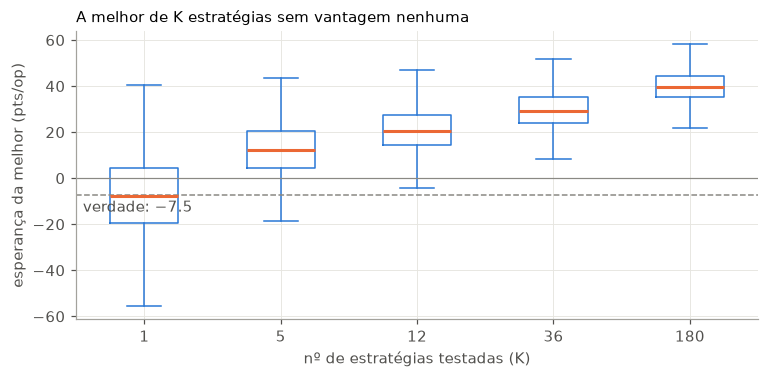

K =   1: esperança mediana da melhor =   -7.7 pts/op;  P(melhor > 0) = 34%
K =   5: esperança mediana da melhor =  +12.3 pts/op;  P(melhor > 0) = 87%
K =  12: esperança mediana da melhor =  +20.7 pts/op;  P(melhor > 0) = 99%
K =  36: esperança mediana da melhor =  +29.2 pts/op;  P(melhor > 0) = 100%
K = 180: esperança mediana da melhor =  +39.6 pts/op;  P(melhor > 0) = 100%


In [8]:
N_OPS, DP_OP, R = 200, 250, 5000
CUSTO = cu.CENARIOS["base"]["custo_pts"]                   # 7,5 pts
ep = DP_OP / np.sqrt(N_OPS)                                 # erro-padrão da esperança de uma estratégia
Ks = [1, 5, 12, 36, 180]
melhores = [(-CUSTO + ep * rng.standard_normal((R, k))).max(axis=1) for k in Ks]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot(melhores, tick_labels=[str(k) for k in Ks], widths=0.5, showfliers=False,
           medianprops=dict(color=LARANJA, lw=2), boxprops=dict(color=AZUL), whiskerprops=dict(color=AZUL),
           capprops=dict(color=AZUL))
ax.axhline(-CUSTO, color=CINZA, lw=1, ls="--"); ax.text(0.55, -CUSTO - 2, f"verdade: −{CUSTO:g}", va="top", color="#52514e")
ax.axhline(0, color=CINZA, lw=0.8)
ax.set_xlabel("nº de estratégias testadas (K)"); ax.set_ylabel("esperança da melhor (pts/op)")
ax.set_title("A melhor de K estratégias sem vantagem nenhuma", loc="left", fontsize=10); plt.show()
for k, m in zip(Ks, melhores):
    print(f"K = {k:3d}: esperança mediana da melhor = {np.median(m):+6.1f} pts/op;  P(melhor > 0) = {np.mean(m > 0):.0%}")

**Leitura:** com 180 estratégias **sem vantagem nenhuma**, a melhor aparece com esperança típica de **+40 pts/op** na validação. A ARIMAX deu +10. No teste, onde não há escolha, ela volta à verdade (−7,5 ± 18). É a **maldição do vencedor**.

Ressalva: as 180 combinações reais não são independentes (regras parecidas dão resultados parecidos), então o efeito real é menor que o desta simulação. Mas a direção é a mesma. Por isso: **testar menos coisas, e sempre ter um período de teste que ninguém usou para escolher nada.**

## 6. Quando a régua 2/√n mente

A régua 2/√n supõe retornos **independentes e de tamanho parecido ao longo do tempo**. Retornos reais têm duas características ("fatos estilizados", ver Cont, 2001):

- **Caudas gordas:** movimentos enormes acontecem bem mais do que numa normal.
- **Agrupamento de volatilidade:** dias agitados vêm seguidos de dias agitados; calmos de calmos. É o que um modelo **GARCH** descreve: a variância de hoje depende do tamanho dos choques recentes.

> **Correção do que eu disse antes:** só as caudas gordas **não** alargam a faixa, se os retornos forem independentes. Quem alarga é o **agrupamento de volatilidade**. Veja:

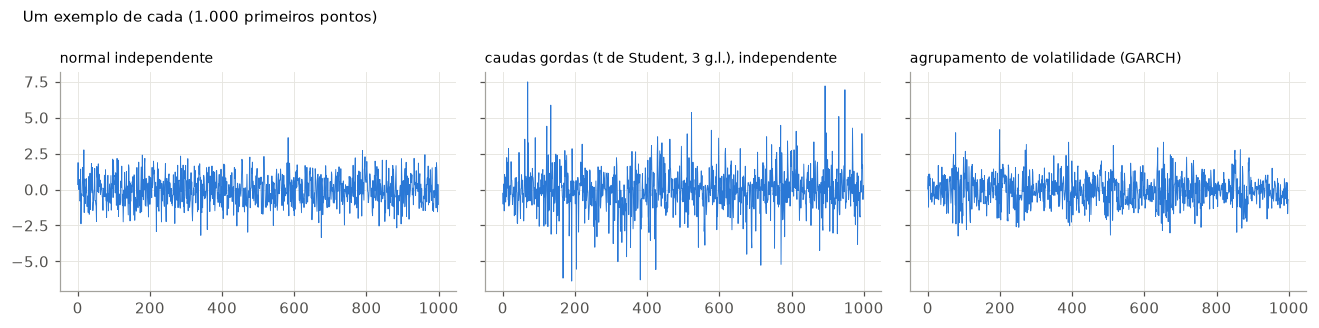

normal independente                                  desvio do ρ₁ = 0.0142 (1/√n = 0.0141);  dentro de ±2/√n: 95%
caudas gordas (t de Student, 3 g.l.), independente   desvio do ρ₁ = 0.0143 (1/√n = 0.0141);  dentro de ±2/√n: 95%
agrupamento de volatilidade (GARCH)                  desvio do ρ₁ = 0.0207 (1/√n = 0.0141);  dentro de ±2/√n: 84%


In [9]:
def garch(R, n, omega=0.05, alpha=0.15, beta=0.80):
    "GARCH(1,1): sigma²(t) = omega + alpha·r(t-1)² + beta·sigma²(t-1). Retornos sem autocorrelação na média."
    s2 = np.full(R, omega / (1 - alpha - beta)); r = np.empty((R, n))
    z = rng.standard_normal((R, n))
    for i in range(n):
        r[:, i] = np.sqrt(s2) * z[:, i]
        s2 = omega + alpha * r[:, i] ** 2 + beta * s2
    return r

R, n = 2000, 5000
series = {"normal independente": rng.standard_normal((R, n)),
          "caudas gordas (t de Student, 3 g.l.), independente": rng.standard_t(3, (R, n)),
          "agrupamento de volatilidade (GARCH)": garch(R, n)}

fig, axs = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (nome, X) in zip(axs, series.items()):
    ax.plot(X[0, :1000], color=AZUL, lw=0.6); ax.set_title(nome, fontsize=9, loc="left")
fig.suptitle("Um exemplo de cada (1.000 primeiros pontos)", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()

for nome, X in series.items():
    r1 = rho1(X)
    print(f"{nome:52s} desvio do ρ₁ = {r1.std():.4f} (1/√n = {1/np.sqrt(n):.4f});  "
          f"dentro de ±2/√n: {np.mean(np.abs(r1) < 2/np.sqrt(n)):.0%}")

**Leitura:** com agrupamento de volatilidade, o ρ₁ de puro ruído "balança" mais do que 1/√n, e a régua clássica declara significância **falsa** com muito mais frequência que 5%.

**A correção:** um erro-padrão **robusto** que leva em conta a variância mudando no tempo:

$$\text{ep}_{\text{robusto}}(\rho_1) = \frac{\sqrt{\sum_t r_t^2\, r_{t-1}^2}}{\sum_t r_t^2}$$

Quando os retornos grandes vêm em grupos, os produtos r²ₜ·r²ₜ₋₁ ficam grandes e o erro-padrão cresce. Com retornos independentes ele volta a ≈ 1/√n.

In [10]:
def ep_robusto(x):
    x = np.atleast_2d(x); x = x - x.mean(axis=1, keepdims=True)
    return np.sqrt((x[:, 1:] ** 2 * x[:, :-1] ** 2).sum(axis=1)) / (x ** 2).sum(axis=1)

for nome, X in series.items():
    print(f"{nome:52s} dentro de ±2·ep_robusto: {np.mean(np.abs(rho1(X)) < 2 * ep_robusto(X)):.0%}")

normal independente                                  dentro de ±2·ep_robusto: 95%
caudas gordas (t de Student, 3 g.l.), independente   dentro de ±2·ep_robusto: 95%


agrupamento de volatilidade (GARCH)                  dentro de ±2·ep_robusto: 95%


Com o erro-padrão robusto, a faixa volta a conter ≈ 95% nos três casos. É ele que vamos usar no WIN, na Seção 8.

## 7. Da correlação ao dinheiro

Suponha que o retorno do próximo candle tenha correlação ρ com o atual, e que a estratégia seja "aposto no sinal que a correlação indica" (se ρ > 0, compro depois de alta; se ρ < 0, vendo depois de alta). Para retornos aproximadamente normais, duas fórmulas resumem tudo:

| | Fórmula | Com ρ = 0,014 |
|---|---|---|
| **Acurácia** (taxa de acerto da direção) | 50% + arcsen(ρ)/π | 50,45% |
| **Ganho bruto por operação** | ≈ ρ × (movimento médio absoluto) | 1,4% do movimento médio |

A intuição da segunda: a parte previsível do próximo retorno é ρ vezes o atual. Apostando no sinal dela, você ganha em média uma fração ρ do tamanho típico do movimento.

Verificação por simulação:

In [11]:
linhas = []
for r in [0.0, 0.005, 0.014, 0.03, 0.05, 0.1, 0.2]:
    x = rng.standard_normal(1_000_000)
    y = r * x + np.sqrt(1 - r**2) * rng.standard_normal(1_000_000)   # y = "próximo retorno"
    ganho = np.sign(x) * y                                             # aposta no sinal (ρ ≥ 0)
    linhas.append(dict(rho=r, acuracia_sim=np.mean(ganho > 0), acuracia_formula=0.5 + np.arcsin(r) / np.pi,
                       ganho_sim_frac=ganho.mean() / np.abs(y).mean(), ganho_formula_frac=r))
pd.DataFrame(linhas).round(4)

,rho,acuracia_sim,acuracia_formula,ganho_sim_frac,ganho_formula_frac
0,0.000,0.5002,0.5000,0.0001,0.000
1,0.005,0.5017,0.5016,0.0050,0.005
2,0.014,0.5041,0.5045,0.0132,0.014
3,0.030,0.5095,0.5096,0.0290,0.030
4,0.050,0.5160,0.5159,0.0499,0.050
5,0.100,0.5320,0.5319,0.1005,0.100
6,0.200,0.5639,0.5641,0.1994,0.200


(`ganho_*_frac` = ganho médio por operação ÷ movimento médio absoluto.)

**Quanto custa uma operação?** O custo de uma operação completa (entrada + saída, 1 contrato) depende de **como** se executa. Os componentes estão nas [notas](../NOTAS.md), Seção 4.7, e o modelo em `custos.py`:

| Cenário | Custo c | Do que é feito |
|---|---|---|
| otimista | 2,5 pts | só as taxas da B3 (≈ R$ 0,50); ordens limitadas, sem pagar spread |
| **base** | **7,5 pts** | taxas + 1 spread (1 tick = 5 pts); ordens a mercado |
| conservador | 12,5 pts | base + 1 tick de slippage |

**Custo de equilíbrio:** em vez de fixar um custo e perguntar "dá lucro?", perguntamos **qual o maior custo que a estratégia aguenta**. É a esperança **bruta** por operação. Para uma correlação ρ e movimento médio absoluto M (em pontos), ela vale ≈ ρ·M. A operação só se paga se ρ·M > c, ou seja:

$$\rho^* = \frac{c}{M}$$

Exemplo, candle de 10 min (Seção 8): M ≈ 118 pts e custo de equilíbrio ρ·M ≈ 0,014 × 118 ≈ 1,7 pt, abaixo até do cenário otimista. No cenário base (c = 7,5), ρ* ≈ 0,063: **4,5 vezes** o ρ₁ medido nesse candle (−0,014), que é o maior do WIN abaixo de 45 min. Isso supõe operar em **todo** candle; filtrar só os candles mais "convictos" ajuda um pouco, mas não muda a ordem de grandeza quando o sinal vem de uma correlação tão pequena.

Aqui aparece a diferença entre **significância estatística** (o efeito existe?) e **significância econômica** (ele é grande o bastante para dar dinheiro?). Com 500 mil candles, um ρ = −0,004 pode ser "significativo", e mesmo assim valer uma fração de ponto por operação.

## 8. No WIN real (desenvolvimento: até 31/12/2024)

Para cada tamanho de candle:

- reamostrar os candles de 1 min;
- calcular o log-retorno **dentro do pregão**: o par (último candle de um dia, primeiro do seguinte) é descartado, para não misturar o gap noturno;
- medir:
  - ρ₁;
  - a faixa clássica e a robusta;
  - o movimento médio absoluto em pontos;
  - o custo de equilíbrio (|ρ₁|·M);
  - o ρ* necessário em cada cenário de custo (2,5 / 7,5 / 12,5 pts).

In [12]:
win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]
print("período:", win.index[0].date(), "→", win.index[-1].date())

CUSTOS = {nome: p["custo_pts"] for nome, p in cu.CENARIOS.items()}   # otimista 2,5 · base 7,5 · conservador 12,5
linhas = []
for k in [1, 2, 3, 5, 7, 10, 15, 20, 30, 45, 60, 120]:
    c = win.resample(f"{k}min").agg({"open": "first", "close": "last"}).dropna()
    dia = pd.Series(c.index.date, index=c.index)
    ret = np.log(c.close).diff()
    ret[dia != dia.shift()] = np.nan                       # sem o gap noturno
    x, y = ret.values[:-1], ret.values[1:]
    ok = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[ok] - np.nanmean(ret), y[ok] - np.nanmean(ret)
    rho = (x * y).sum() / np.sqrt((x**2).sum() * (y**2).sum())
    ep_rob = np.sqrt((x**2 * y**2).sum()) / np.sqrt((x**2).sum() * (y**2).sum())
    M = (ret.abs() * c.close).mean()                       # movimento médio absoluto, em pontos
    linhas.append(dict(candle_min=k, n=ok.sum(), rho1=rho, faixa_classica=2 / np.sqrt(ok.sum()),
                       faixa_robusta=2 * ep_rob, mov_medio_pts=M, custo_equilibrio_pts=abs(rho) * M,
                       **{f"rho_nec_{nome}": c / M for nome, c in CUSTOS.items()}))
tab = pd.DataFrame(linhas)
tab["signif_classica"] = tab.rho1.abs() > tab.faixa_classica
tab["signif_robusta"] = tab.rho1.abs() > tab.faixa_robusta
tab.round(4)

período: 2020-10-15 → 2024-12-30


,candle_min,n,rho1,faixa_classica,faixa_robusta,mov_medio_pts,custo_equilibrio_pts,rho_nec_otimista,rho_nec_base,rho_nec_conservador,signif_classica,signif_robusta
0,1,511868,-0.0036,0.0028,0.0079,37.5613,0.1354,0.0666,0.1997,0.3328,True,False
1,2,255496,-0.0047,0.0040,0.0101,53.2453,0.2487,0.0470,0.1409,0.2348,True,False
2,3,170027,-0.0110,0.0049,0.0116,65.2012,0.7170,0.0383,0.1150,0.1917,True,False
3,5,100920,-0.0010,0.0063,0.0123,84.2177,0.0821,0.0297,0.0891,0.1484,False,False
4,7,72389,-0.0056,0.0074,0.0117,99.6327,0.5595,0.0251,0.0753,0.1255,False,False
5,10,50001,-0.0140,0.0089,0.0167,118.1919,1.6566,0.0212,0.0635,0.1058,True,False
6,15,32713,-0.0007,0.0111,0.0178,143.8395,0.0962,0.0174,0.0521,0.0869,False,False
7,20,24334,-0.0050,0.0128,0.0208,165.4253,0.8189,0.0151,0.0453,0.0756,False,False
8,30,15425,-0.0006,0.0161,0.0224,204.7028,0.1229,0.0122,0.0366,0.0611,False,False
9,45,9840,0.0139,0.0202,0.0282,249.5048,3.4600,0.0100,0.0301,0.0501,False,False


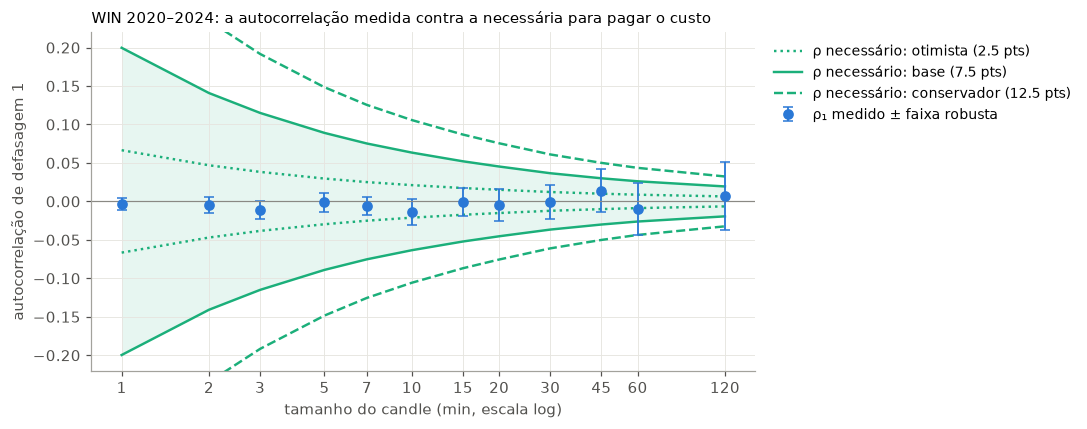

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
k = tab.candle_min
ax.fill_between(k, -tab.rho_nec_base, tab.rho_nec_base, color=VERDE, alpha=0.10, lw=0)
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    col = tab[f"rho_nec_{nome}"]
    ax.plot(k, col, color=VERDE, lw=1.6, ls=estilo, label=f"ρ necessário: {nome} ({CUSTOS[nome]:g} pts)")
    ax.plot(k, -col, color=VERDE, lw=1.6, ls=estilo)
ax.errorbar(k, tab.rho1, yerr=tab.faixa_robusta, fmt="o", color=AZUL, ms=6, capsize=3, lw=1.2,
            label="ρ₁ medido ± faixa robusta")
ax.axhline(0, color=CINZA, lw=0.8)
ax.set_xscale("log"); ax.set_xticks(k, [str(v) for v in k]); ax.minorticks_off()
ax.set_ylim(-0.22, 0.22)
ax.set_xlabel("tamanho do candle (min, escala log)"); ax.set_ylabel("autocorrelação de defasagem 1")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.set_title("WIN 2020–2024: a autocorrelação medida contra a necessária para pagar o custo", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

**Leitura:**

- **Régua clássica × robusta:** com a clássica (2/√n), 4 tamanhos pareciam significativos (1, 2, 3 e 10 min). Com a robusta, **nenhum**. A faixa robusta é de 1,3 a 3 vezes a clássica, porque o WIN tem forte agrupamento de volatilidade (Seção 6). O p-valor de 0,0017 da Seção 4 (10 min) passa a ≈ 0,09 com o erro-padrão robusto.
- **Cenário base (7,5 pts), candles até 45 min:** o ρ necessário fica acima do ρ₁ medido e da faixa de ruído. Mesmo que o efeito fosse real, **não pagaria o custo**: até 30 min, o custo de equilíbrio é de 0,1 a 1,7 pt por operação, abaixo até do cenário otimista (2,5).
- **Onde o ρ necessário cai dentro da faixa de ruído** (60 e 120 min no cenário base; a partir de 15 min no otimista), o problema é outro: **não há dados suficientes para saber**. Um efeito lucrativo poderia existir e não conseguiríamos separá-lo do ruído com 4 anos de dados.
- **Atenção à armadilha:** em 45–120 min, o custo de equilíbrio estimado (≈ 3 pts) passa do cenário otimista. Mas esses ρ₁ **não são significativos** e trocam de sinal (+0,014, −0,010, +0,007): é ruído, não oportunidade. Sempre ler o custo de equilíbrio junto com o seu erro.
- **Para o projeto:** procurar o "melhor tamanho de candle" para um ARIMA é procurar onde não há nada. Em média, e linearmente, um candle não prevê o seguinte em nenhuma escala. Se existe algo explorável, ele será:
  - **condicional:** em certos horários, depois de grandes movimentos, no gap de abertura, em certos regimes de volatilidade;
  - ou estará na **volatilidade**, não na direção.

  É isso que a análise exploratória vai investigar.

Nota: o movimento médio absoluto (a média) é maior que o mediano (37 contra 25 pts em 1 min), porque as caudas gordas puxam a média para cima. A fórmula ρ* = c/M usa a média.

## 9. Resumo: o que levar deste notebook

| Conceito | Em uma frase |
|---|---|
| Correlação | Mede relação **linear** de −1 a +1; ρ = 0,05 já é invisível a olho nu. |
| Autocorrelação ρ₁ | Correlação do retorno com o anterior; é o que a parte AR do ARIMA explora. |
| Ruído amostral | Mesmo sem efeito, o valor medido balança ≈ 1/√n; 95% fica em ±2/√n. |
| p-valor | Chance de ver algo tão extremo **se fosse só ruído**; não mede o tamanho do efeito. |
| Comparações múltiplas | Testando muitas coisas, alguma "funciona" por acaso; a melhor de muitas decepciona fora da amostra. |
| Agrupamento de volatilidade | Alarga o ruído real; use o erro-padrão robusto. |
| Significância econômica | O efeito precisa pagar o custo: o custo de equilíbrio (≈ ρ·M) precisa superar c, que vai de 2,5 a 12,5 pts conforme a execução. |

### Exercícios

1. Na Seção 2, com φ = 0,05, você consegue ver diferença no gráfico? E no ρ₁ medido com n = 200? E com n = 20.000?
2. Na Seção 5, quantas estratégias sem vantagem (K) são precisas para a melhor parecer ter +20 pts/op com 200 operações? E com 2.000 operações?
3. Na Seção 6, aumente `alpha` do GARCH (mantendo alpha + beta < 1). O que acontece com a fração dentro de ±2/√n?
4. Na Seção 8, qual seria o custo máximo para que 10 min fosse viável, se o ρ₁ medido fosse real? Isso é realista para um operador pessoa física (Seção 7)?
5. Calcule ρ₁ só para o **primeiro candle depois da abertura** (o par: retorno do 1º candle × retorno do 2º). O resultado é parecido com o geral? (É uma prévia da análise condicional que vem depois.)

### Leituras

- **StatQuest** (YouTube, Josh Starmer): vídeos curtos sobre correlação, p-valores e *multiple testing*.
- **Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*** (otexts.com/fpp3, grátis): cap. 2.8–2.9 (autocorrelação, ruído branco) e cap. 9 (ARIMA).
- **Morettin & Toloi, *Análise de Séries Temporais***: a referência em português.
- **R. Cont (2001), "Empirical properties of asset returns: stylized facts and statistical issues"**: os fatos estilizados da Seção 6.
- **Bailey, Borwein, López de Prado & Zhu (2014), "Pseudo-Mathematics and Financial Charlatanism"**: a Seção 5 aplicada a backtests.